# Model Calibration and Lift Analysis

This notebook evaluates the purchase propensity model beyond a single accuracy number.

Three questions are asked, in order:

1. **Calibration.** When the model says a user has a 30 percent chance of buying, do 30 percent
   of such users actually buy? A model can rank users perfectly and still be badly calibrated.
2. **Lift.** If a campaign targets only the highest scored users, how much better is that than
   contacting the same number of users at random?
3. **Cumulative gains.** What share of all actual purchasers is captured by contacting the top
   N percent of the ranked population?

All numbers below are computed on the test split, whose feature reference date and target window
both sit strictly later than the training split's.

In [1]:
# Notebook bootstrap: make the project importable and anchor relative paths.
# Jupyter starts the kernel in the notebook's own directory, so the project root has to
# be put on sys.path explicitly, exactly as the runnable modules under src/ do.
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

print("Project root:", PROJECT_ROOT)

Project root: /home/nikhil/tindal-data-pipeline/consumer-telemetry


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import Image, display

from src.models.evaluation import (
    capture_at_population_fraction,
    compute_calibration_metrics,
    compute_cumulative_gains,
    compute_decile_lift,
    run_evaluation_pipeline,
)

pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_float("full")

results = run_evaluation_pipeline()

y_test = results["y_test"]
proba_before = results["proba_before"]
proba_after = results["proba_after"]
lift_df = results["lift_table"]
gains_df = results["gains_curve"]
summary = results["summary"]

Fitting uncalibrated propensity model...
Selecting a calibration method by cross-validated Brier score on train...


  Uncalibrated CV Brier : 0.1385
  isotonic   CV Brier : 0.1393
  sigmoid    CV Brier : 0.1366
  Selected method       : sigmoid
Fitting sigmoid calibrated model on the training matrix...



--- Calibration on the Test Split ---
Metric             |   Uncalibrated |        Sigmoid
------------------------------------------------------
brier_score        |         0.1141 |         0.1097
log_loss           |         0.3696 |         0.3576
roc_auc            |         0.9136 |         0.9230
mean_predicted     |         0.4364 |         0.4084
observed_rate      |         0.3950 |         0.3950

  Recalibration helps: sigmoid lowers cross-validated Brier score.

--- Decile Lift (Test Split) ---
Decile | Users | Mean Pred | Actual Rate |  Lift | Cum Capture
--------------------------------------------------------------------
     1 |    40 |    0.8785 |      1.0000 |  2.53 |      25.32%
     2 |    40 |    0.8201 |      0.8500 |  2.15 |      46.84%
     3 |    40 |    0.7487 |      0.7000 |  1.77 |      64.56%
     4 |    40 |    0.6476 |      0.6750 |  1.71 |      81.65%
     5 |    40 |    0.4452 |      0.4000 |  1.01 |      91.77%
     6 |    40 |    0.2073 |      0.150


Saved calibrated model to  /home/nikhil/tindal-data-pipeline/consumer-telemetry/src/models/artifacts/propensity_lgbm_calibrated.joblib
Saved calibration plot to  /home/nikhil/tindal-data-pipeline/consumer-telemetry/src/models/artifacts/propensity_calibration_curve.png
Saved lift chart to        /home/nikhil/tindal-data-pipeline/consumer-telemetry/src/models/artifacts/propensity_lift_chart.png
Saved gains chart to       /home/nikhil/tindal-data-pipeline/consumer-telemetry/src/models/artifacts/propensity_cumulative_gains.png
Saved ROC/PR curves to     /home/nikhil/tindal-data-pipeline/consumer-telemetry/src/models/artifacts/propensity_roc_pr_curves.png
Saved summary to           /home/nikhil/tindal-data-pipeline/consumer-telemetry/src/models/artifacts/propensity_evaluation_summary.json


## 1. Calibration

The reliability diagram plots predicted probability against observed purchase frequency. The
diagonal is perfect calibration. The histogram underneath shows how the predicted scores are
distributed, which matters because a reliability curve over a narrow score range says very little.

The calibration method is chosen by cross-validated Brier score **on the training matrix**, never
on the test split, so the test numbers below carry no selection bias.

In [3]:
print("Calibration method selected:", summary["calibration_method"])
print("Recalibration improves on uncalibrated:", summary["method_selection"]["improves_on_uncalibrated"])

cv = summary["method_selection"]["cv_scores"]
print(pl.DataFrame([
    {"variant": name, **{k: round(v, 4) for k, v in scores.items()}}
    for name, scores in cv.items()
]))

Calibration method selected: sigmoid
Recalibration improves on uncalibrated: True
shape: (3, 4)
┌──────────────┬─────────────┬──────────┬─────────┐
│ variant      ┆ brier_score ┆ log_loss ┆ roc_auc │
│ ---          ┆ ---         ┆ ---      ┆ ---     │
│ str          ┆ f64         ┆ f64      ┆ f64     │
╞══════════════╪═════════════╪══════════╪═════════╡
│ uncalibrated ┆ 0.1385      ┆ 0.4403   ┆ 0.8729  │
│ isotonic     ┆ 0.1393      ┆ 0.6158   ┆ 0.8702  │
│ sigmoid      ┆ 0.1366      ┆ 0.4352   ┆ 0.8741  │
└──────────────┴─────────────┴──────────┴─────────┘


In [4]:
before = compute_calibration_metrics(y_test, proba_before)
after = compute_calibration_metrics(y_test, proba_after)

print(pl.DataFrame([
    {"metric": k, "uncalibrated": round(before[k], 4), "calibrated": round(after[k], 4)}
    for k in ("brier_score", "log_loss", "roc_auc", "mean_predicted", "observed_rate")
]))

shape: (5, 3)
┌────────────────┬──────────────┬────────────┐
│ metric         ┆ uncalibrated ┆ calibrated │
│ ---            ┆ ---          ┆ ---        │
│ str            ┆ f64          ┆ f64        │
╞════════════════╪══════════════╪════════════╡
│ brier_score    ┆ 0.1141       ┆ 0.1097     │
│ log_loss       ┆ 0.3696       ┆ 0.3576     │
│ roc_auc        ┆ 0.9136       ┆ 0.923      │
│ mean_predicted ┆ 0.4364       ┆ 0.4084     │
│ observed_rate  ┆ 0.395        ┆ 0.395      │
└────────────────┴──────────────┴────────────┘


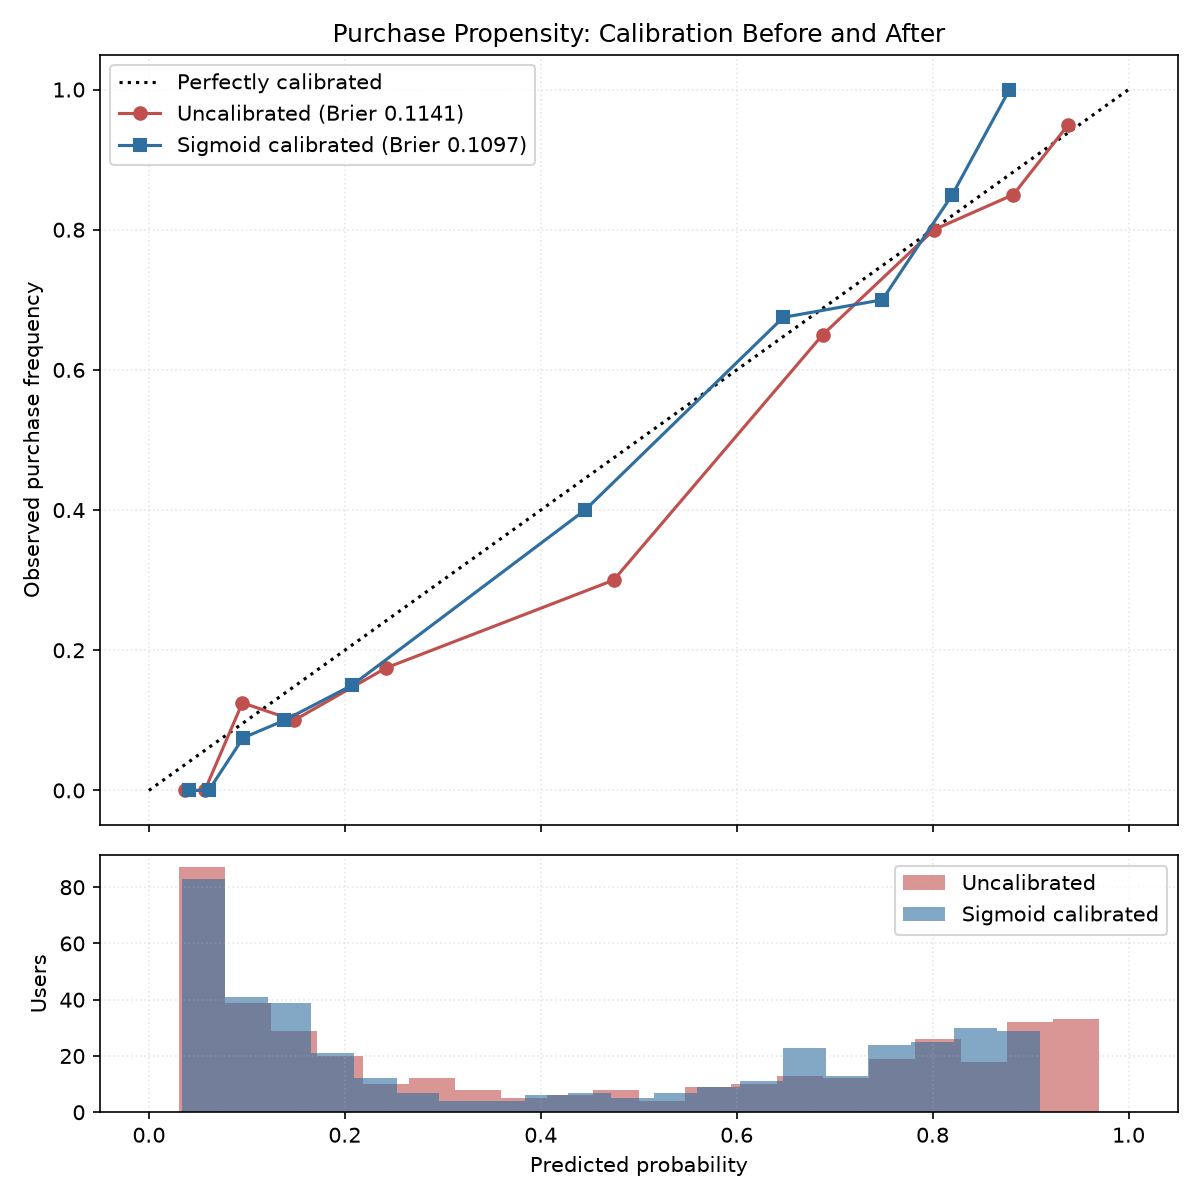

In [5]:
display(Image(filename=str(results["paths"]["calibration_plot"])))

### Reading the calibration result

The propensity model is trained against binary log loss, which is a proper scoring rule: it is
minimized only when the predicted probabilities match the true conditional probabilities. A model
fitted that way starts out close to calibrated, so there is no large miscalibration to correct, and
both curves track the diagonal reasonably closely.

What the cross-validated Brier scores above decide is whether the remaining gap is worth closing.
They are all within a few thousandths of each other, so whichever variant wins does so by a narrow
margin rather than by fixing a broken model. The printed verdict in the previous cell is the one to
trust, since it is recomputed on every run; the practical reading either way is that the score can
be treated as an expected purchase rate without a large correction.

This is worth stating carefully because it is a common trap: calibration is often applied
reflexively after training. It genuinely matters for models fitted on a non-proper objective, such
as a hinge loss or a tree ensemble optimized purely for AUC, where predicted scores are only ranks
and carry no probabilistic meaning. Here the objective already targets probability quality, so
calibration is a small refinement rather than a repair.

## 2. Lift by Decile

Users are sorted by predicted probability in descending order and split into ten equal groups.
Decile 1 is the highest scored 10 percent of users.

Lift is a decile's observed purchase rate divided by the overall population rate. One important
ceiling to keep in mind: lift cannot exceed `1 / base_rate`. With a test base rate near 40 percent,
no model can score a top decile lift above about 2.5, so a value close to that is near perfect
separation rather than a modest result.

In [6]:
base_rate = float(np.mean(y_test))
print(f"Test base rate      : {base_rate:.4f}")
print(f"Maximum lift ceiling: {1.0 / base_rate:.2f}")
print(f"Observed top decile : {lift_df['lift'][0]:.2f}")
print()
print(lift_df.select([
    "decile", "users", "mean_predicted_probability",
    "actual_purchasers", "actual_purchase_rate", "lift", "cumulative_capture_pct",
]))

Test base rate      : 0.3950
Maximum lift ceiling: 2.53
Observed top decile : 2.53

shape: (10, 7)
┌────────┬───────┬────────────────┬────────────────┬───────────────┬───────────────┬───────────────┐
│ decile ┆ users ┆ mean_predicted ┆ actual_purchas ┆ actual_purcha ┆ lift          ┆ cumulative_ca │
│ ---    ┆ ---   ┆ _probability   ┆ ers            ┆ se_rate       ┆ ---           ┆ pture_pct     │
│ i64    ┆ i64   ┆ ---            ┆ ---            ┆ ---           ┆ f64           ┆ ---           │
│        ┆       ┆ f64            ┆ i64            ┆ f64           ┆               ┆ f64           │
╞════════╪═══════╪════════════════╪════════════════╪═══════════════╪═══════════════╪═══════════════╡
│ 1      ┆ 40    ┆ 0.878497663579 ┆ 40             ┆ 1             ┆ 2.53164556962 ┆ 0.25316455696 │
│        ┆       ┆ 2663           ┆                ┆               ┆ 0253          ┆ 202533        │
│ 2      ┆ 40    ┆ 0.820126392292 ┆ 34             ┆ 0.85          ┆ 2.15189873417 ┆ 0.468354

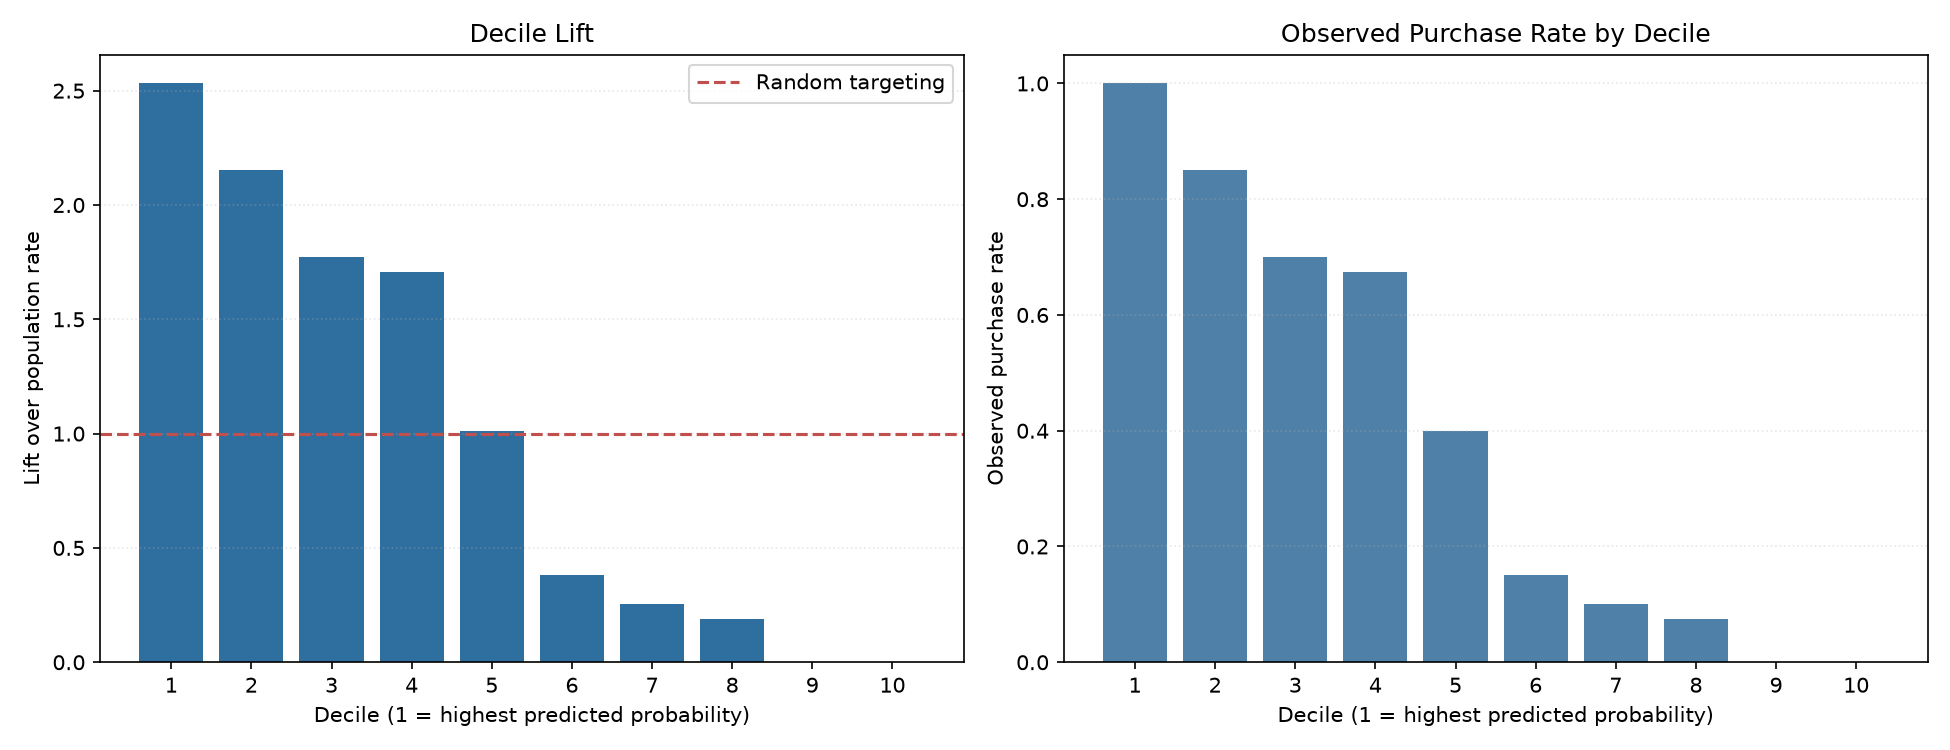

In [7]:
display(Image(filename=str(results["paths"]["lift_plot"])))

## 3. Cumulative Gains

The gains curve answers the targeting question directly: contacting the top N percent of the ranked
population reaches what share of everyone who actually purchases? The diagonal is random targeting,
where contacting 20 percent of users reaches 20 percent of purchasers.

In [8]:
for fraction in (0.1, 0.2, 0.3, 0.5):
    captured = capture_at_population_fraction(gains_df, fraction)
    print(f"  Top {fraction:>4.0%} of users captures {captured:>6.1%} of all purchasers "
          f"({captured / fraction:.2f}x random)")

  Top  10% of users captures  25.3% of all purchasers (2.53x random)
  Top  20% of users captures  46.8% of all purchasers (2.34x random)
  Top  30% of users captures  64.6% of all purchasers (2.15x random)
  Top  50% of users captures  91.8% of all purchasers (1.84x random)


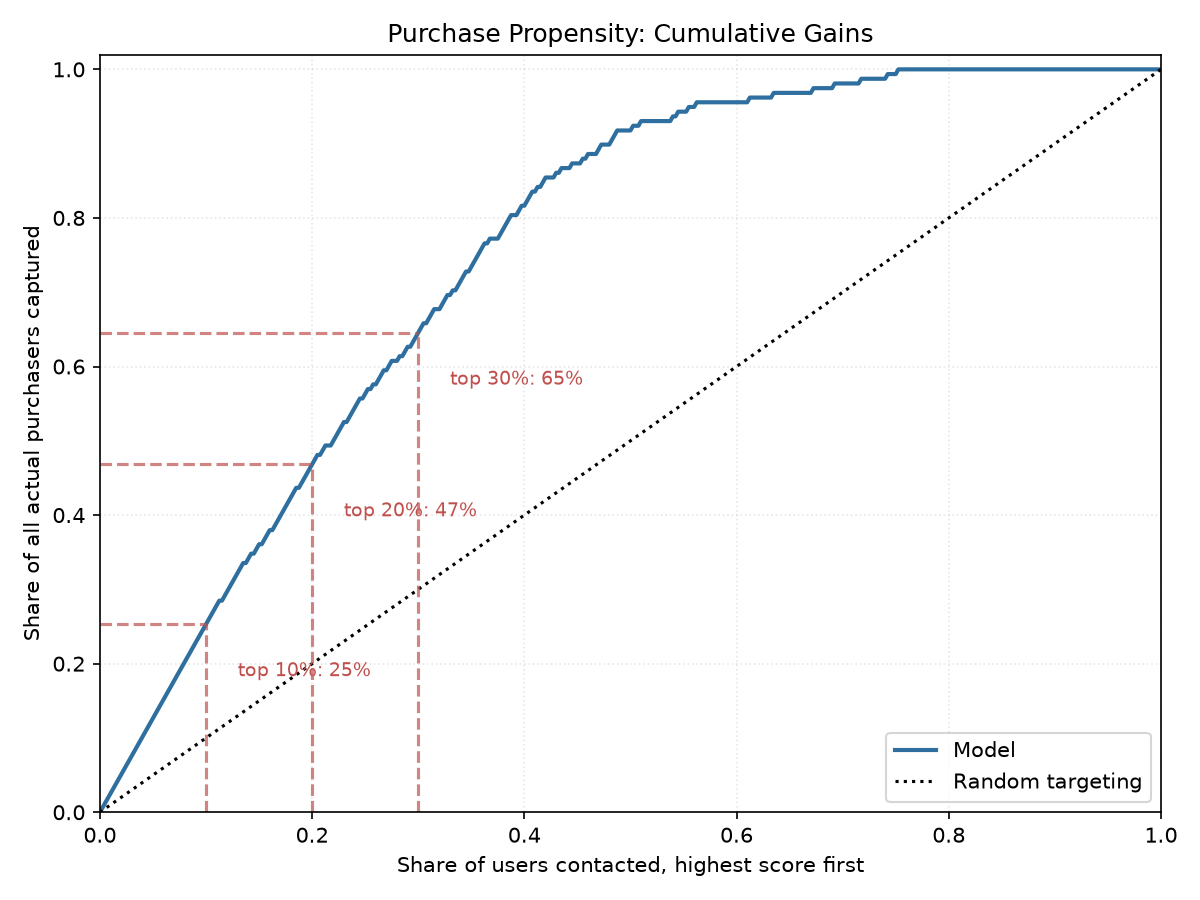

In [9]:
display(Image(filename=str(results["paths"]["gains_plot"])))

## 4. Conclusions

- **Ranking quality is strong.** Observed purchase rates fall monotonically from the top deciles to
  the bottom, and the top decile sits close to the theoretical lift ceiling imposed by the base rate.
- **The scores are usable as probabilities.** The model is already well calibrated, so a predicted
  0.8 can be read as roughly an 80 percent chance of purchase without post-processing.
- **The bottom deciles are the actionable finding.** The lowest two deciles contain no purchasers
  in the test window against a population rate near 40 percent. Suppressing them from a retention campaign removes
  roughly a fifth of the contact cost while giving up very little revenue.

The precise capture figures printed above are the ones to quote, since they are recomputed on every
run of this notebook rather than copied into prose.